# When and where are Swiss trains crowded?

SBB publishes a daily **occupancy forecast** for the next three months of train traffic of SBB, BLS, Thurbo, SOB and Zentralbahn (zb).
For each train, at each stop and for each class, it gives one of three levels: *many seats*, *few seats*, or *standing room only*.

Source: [Occupancy Forecast SIRI Dataset](https://opendata.swiss/en/dataset/occupancy-forecast-siri-dataset) on opendata.swiss (SIRI-ET XML, about 100 MB zipped, 6 GB unzipped).

This notebook answers five questions:

1. What does the forecast look like for each operator?
2. At which hours and on which days are trains crowded?
3. How does crowding change over the next three months?
4. Where are trains crowded — and does that change between morning and evening (the *commuter tide*)?
5. How do 1st and 2nd class compare, and where on its trip is a train most crowded?

**Crowded** in this notebook means *few seats* or *standing room only*.

In [1]:
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap, ListedColormap

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from crowding.parse import LEVEL_LABELS
from crowding.theme import DIVERGING, LEVEL_COLORS, MUTED, CATEGORICAL, use_matplotlib

use_matplotlib()
DATA = ROOT / "data"
if not (DATA / "departures.parquet").exists():
    subprocess.run([sys.executable, "-m", "crowding.build", "--data-dir", str(DATA)], cwd=ROOT, check=True)

## 1. The data

`python -m crowding.build` downloads the zip, parses the first 14 forecast days in full (one row per departure of a train from a stop),
and counts the levels for all forecast days. Here we load the result.

In [2]:
dep = pd.read_parquet(DATA / "departures.parquet")
daily = pd.read_parquet(DATA / "daily_levels.parquet")
stations = pd.read_parquet(DATA / "stations.parquet")
dep[["occ_1st", "occ_2nd"]] = dep[["occ_1st", "occ_2nd"]].astype("float64")
dep["weekday"] = dep["departure"].dt.day_of_week
dep["crowded"] = dep["occ_2nd"] >= 2
print(f"{len(dep):,} departures, {dep[['date', 'operator', 'train']].drop_duplicates().shape[0]:,} train runs, "
      f"{dep['stop_id'].nunique():,} stops, {dep['date'].min():%Y-%m-%d} to {dep['date'].max():%Y-%m-%d}")
dep.head()

1,421,624 departures, 135,848 train runs, 1,110 stops, 2026-10-27 to 2026-11-09


,date,operator,train,seq,stop_id,stop_name,departure,occ_1st,occ_2nd,operator_name,hour,trip_len,weekday,crowded
0,2026-10-27,11,6147,0,8501500,Martigny,2026-10-27 04:22:00+01:00,1.0,1.0,SBB,4,16,1,False
1,2026-10-27,11,6147,1,8501501,Charrat-Fully,2026-10-27 04:25:00+01:00,1.0,1.0,SBB,4,16,1,False
2,2026-10-27,11,6147,2,8501502,Saxon,2026-10-27 04:29:00+01:00,1.0,1.0,SBB,4,16,1,False
3,2026-10-27,11,6147,3,8501503,Riddes,2026-10-27 04:32:00+01:00,1.0,1.0,SBB,4,16,1,False
4,2026-10-27,11,6147,4,8501504,Chamoson-St-Pierre-de-Clages,2026-10-27 04:36:00+01:00,1.0,1.0,SBB,4,16,1,False


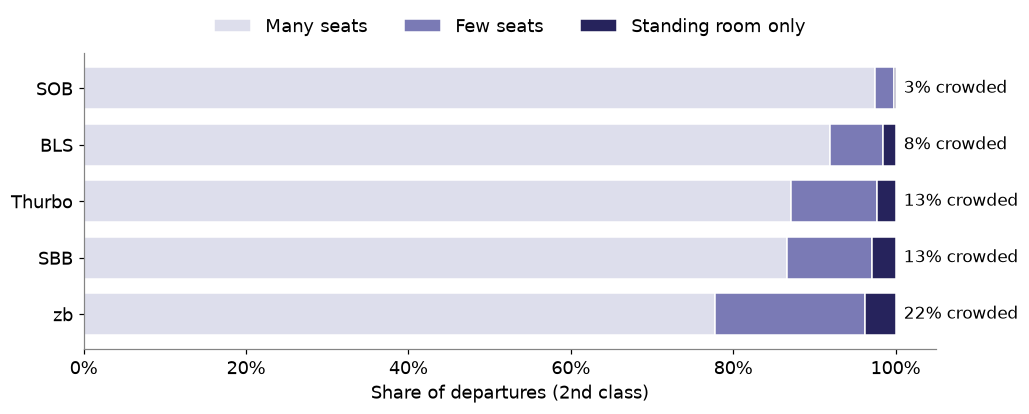

In [3]:
share = (dep.groupby("operator_name")["occ_2nd"].value_counts(normalize=True).unstack()[[1, 2, 3]]
         .sort_values(1))
ax = share.plot.barh(stacked=True, color=[LEVEL_COLORS[l] for l in share.columns], edgecolor="white",
                     figsize=(10, 3.5), width=0.75)
ax.legend([LEVEL_LABELS[l] for l in share.columns], ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False)
ax.set_xlabel("Share of departures (2nd class)")
ax.set_ylabel("")
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
for i, (op, row) in enumerate(share.iterrows()):
    ax.text(1.01, i, f"{row[2] + row[3]:.0%} crowded", va="center", fontsize=11)
plt.show()

Most departures have *many seats*. Zentralbahn (zb, Luzern–Engelberg/Interlaken) is the exception: more than one in five of its departures is crowded.
SOB is the least crowded operator.

## 2. When are trains crowded?

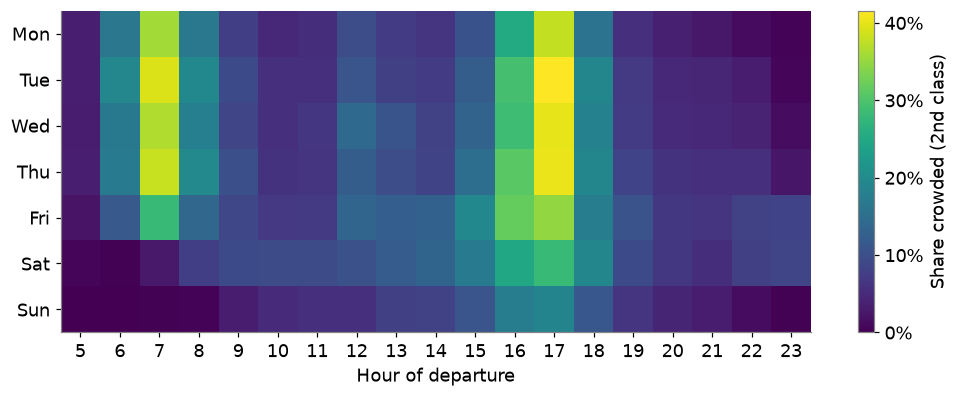

In [4]:
heat = dep.groupby(["weekday", "hour"])["crowded"].mean().unstack().reindex(columns=range(5, 24))
fig, ax = plt.subplots(figsize=(11, 3.8))
im = ax.imshow(heat.values, aspect="auto", cmap="viridis", vmin=0)
ax.set_yticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
ax.set_xticks(range(len(heat.columns)), heat.columns)
ax.set_xlabel("Hour of departure")
ax.grid(False)
fig.colorbar(im, ax=ax, label="Share crowded (2nd class)", format=lambda x, _: f"{x:.0%}")
plt.show()

Two rush hours stand out on weekdays. The **evening rush (16:00–18:00) is a bit stronger and longer than the morning rush (07:00)**.
On Friday the evening rush starts earlier. Saturday and Sunday have only a smaller afternoon peak.

## 3. The next three months

The zip contains about 93 forecast days. A full parse of all of them takes some minutes, so `count_levels` only counts the level tags per day.

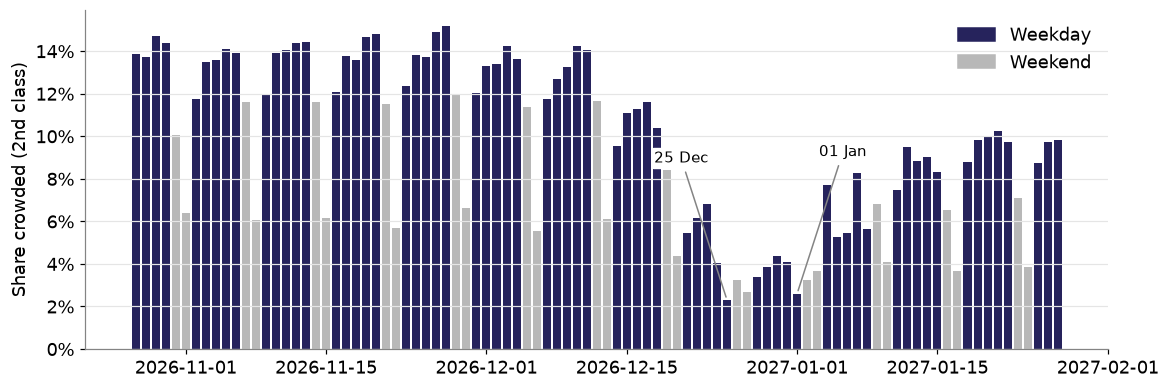

In [5]:
d2 = daily[(daily["fare_class"] == 2) & daily["level"].notna()].groupby(["date", "level"])["n"].sum().unstack()
cal = ((d2[2] + d2[3]) / d2.sum(axis=1)).rename("crowded").to_frame()
cal["weekend"] = cal.index.day_of_week >= 5
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(cal.index, cal["crowded"], color=np.where(cal["weekend"], MUTED, CATEGORICAL[0]), width=0.8)
ax.yaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.set_ylabel("Share crowded (2nd class)")
for day, dx in [(pd.Timestamp("2026-12-25"), -30), (pd.Timestamp("2027-01-01"), 30)]:
    if day in cal.index:
        ax.annotate(f"{day:%d %b}", (day, cal.loc[day, "crowded"]), xytext=(dx, 90), textcoords="offset points", ha="center", fontsize=10,
                    bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none"),
                    arrowprops=dict(arrowstyle="-", color="#848484"))
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=CATEGORICAL[0]), plt.Rectangle((0, 0), 1, 1, color=MUTED)],
          labels=["Weekday", "Weekend"], frameon=False, loc="upper right")
plt.show()

The weekly rhythm continues through the whole period. The holidays are clear: **Christmas Day and New Year's Day are the quietest days**,
and the two weeks around them are like one long weekend (school holidays).

January is less crowded than November in general. This can be a real seasonal effect, or the forecast can be more careful for days far ahead.
This data alone cannot tell which. To find out, collect the forecast every day and compare it with later versions.

## 4. Where are trains crowded?

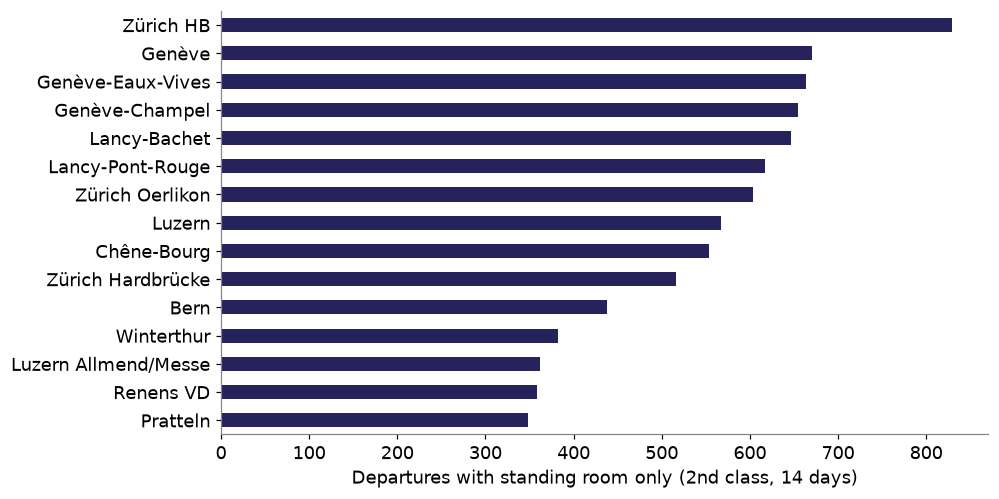

In [6]:
standing = (dep[dep["occ_2nd"] == 3].groupby("stop_name").size().nlargest(15).sort_values())
ax = standing.plot.barh(color=CATEGORICAL[0], figsize=(9, 5))
ax.set_xlabel("Departures with standing room only (2nd class, 14 days)")
ax.set_ylabel("")
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
plt.show()

Zürich HB leads, but the Geneva area has many entries: the Léman Express stations (Genève-Eaux-Vives, Champel, Lancy) are among the most crowded stops in the country.

### The commuter tide

On weekdays, compare the mean level at each station in the **morning** (06:00–09:00) with the **evening** (16:00–19:00).
The tilt is `(morning − evening) / (morning + evening)`: +1 means only crowded in the morning, −1 only in the evening.

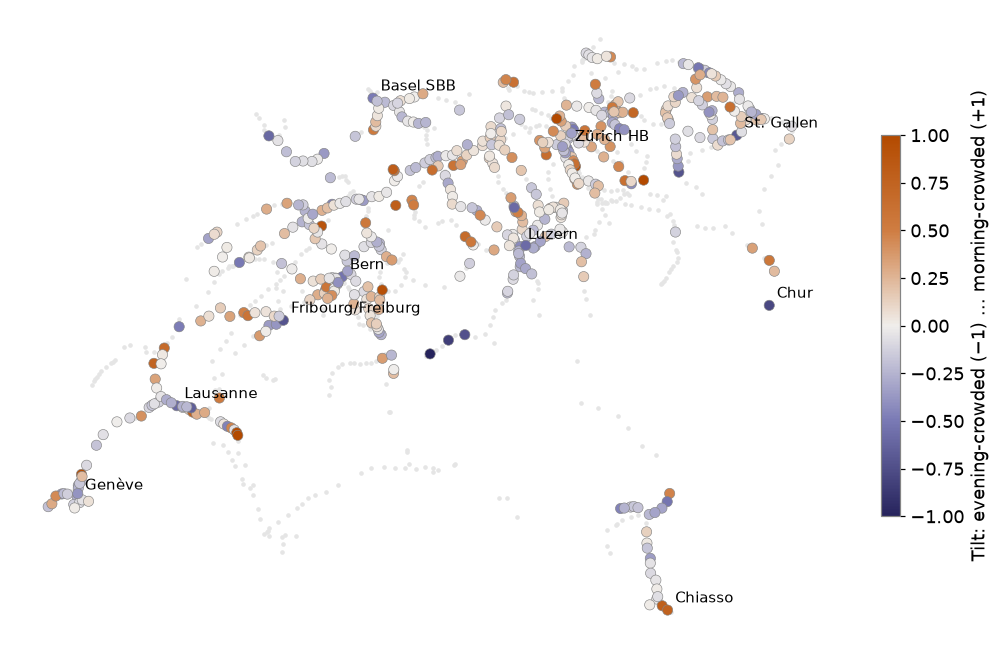

,name,am,pm,tilt
436,Interlaken Ost,0.00,0.33,-1.00
400,Rorschach Hafen,0.02,0.35,-0.91
469,Oberried am Brienzersee,0.09,1.02,-0.84
481,Chur,0.04,0.37,-0.79
470,Brienz,0.04,0.23,-0.73
376,Wattwil,0.04,0.23,-0.72
239,Fribourg/Freiburg,0.07,0.41,-0.71
396,St. Gallen,0.10,0.54,-0.69
45,Dotzigen,0.31,0.02,0.90
64,Pont-Céard,0.28,0.01,0.94


In [7]:
wk = dep[dep["weekday"] < 5].assign(load=dep["occ_2nd"] - 1)
wk["window"] = np.select([wk["hour"].between(6, 8), wk["hour"].between(16, 18)], ["am", "pm"], "other")
per = wk[wk["window"] != "other"].groupby(["stop_id", "window"])["load"].mean().unstack().fillna(0)
total = wk.groupby("stop_id").size()
per = per[(per["am"] + per["pm"] > 0.25) & (total.reindex(per.index) >= 400)]
per["tilt"] = (per["am"] - per["pm"]) / (per["am"] + per["pm"])
tide = per.reset_index().merge(stations, on="stop_id")

cmap = LinearSegmentedColormap.from_list("tide", DIVERGING)
fig, ax = plt.subplots(figsize=(12, 7.5))
ax.scatter(stations["lon"], stations["lat"], s=4, color="#e5e5e5")
sc = ax.scatter(tide["lon"], tide["lat"], c=tide["tilt"], cmap=cmap, vmin=-1, vmax=1, s=45,
                edgecolor="#848484", linewidth=0.4)
for name in ["Zürich HB", "Bern", "Basel SBB", "Genève", "Lausanne", "Luzern", "St. Gallen", "Chur", "Chiasso", "Fribourg/Freiburg"]:
    row = tide[tide["name"] == name]
    if len(row):
        ax.annotate(name, (row["lon"].iloc[0], row["lat"].iloc[0]), xytext=(5, 5), textcoords="offset points", fontsize=10)
ax.set_aspect(1 / np.cos(np.radians(46.8)))
ax.axis("off")
cb = fig.colorbar(sc, ax=ax, shrink=0.6, label="Tilt: evening-crowded (−1) … morning-crowded (+1)")
plt.show()
tide.sort_values("tilt")[["name", "am", "pm", "tilt"]].round(2).iloc[np.r_[0:8, -8:0]]

The pattern is clear. **Departures from city hubs are crowded in the evening** (Bern, Lausanne, St. Gallen, Fribourg, Chur): people go home after work.
**Departures from suburbs and towns are crowded in the morning**: people leave for work. The southern border stations (Chiasso, Balerna) show the morning flow of commuters from Italy.

## 5. First and second class, and the shape of a trip

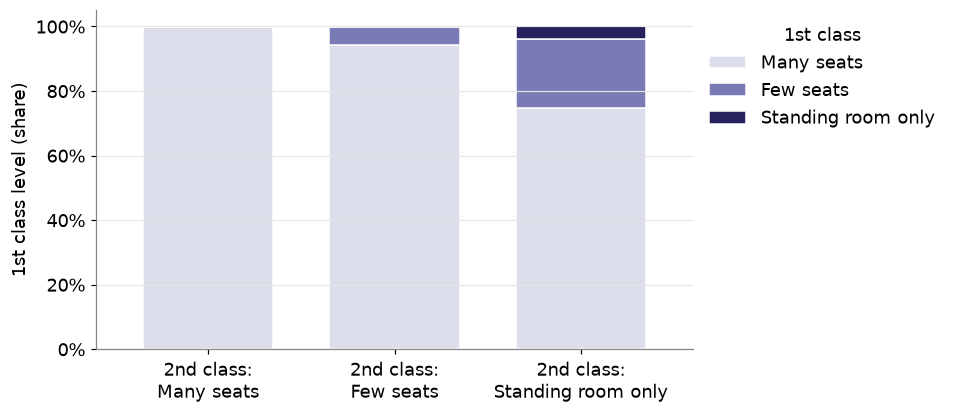

In [8]:
ct = pd.crosstab(dep["occ_2nd"], dep["occ_1st"], normalize="index")[[1, 2, 3]]
ax = ct.plot.bar(stacked=True, color=[LEVEL_COLORS[l] for l in ct.columns], edgecolor="white", figsize=(7, 4), rot=0, width=0.7)
ax.set_xticklabels([f"2nd class:\n{LEVEL_LABELS[l]}" for l in ct.index])
ax.set_xlabel("")
ax.set_ylabel("1st class level (share)")
ax.yaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.legend([LEVEL_LABELS[l] for l in ct.columns], title="1st class", frameon=False, bbox_to_anchor=(1, 1))
ax.grid(axis="x", visible=False)
plt.show()

When 2nd class has *standing room only*, 1st class still has *many seats* in about three of four cases. An upgrade is often a good option on the busiest trains.

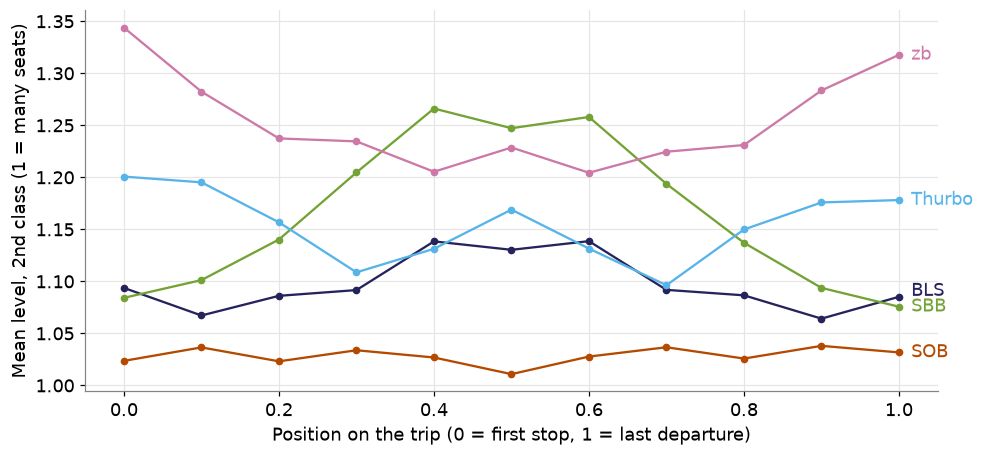

In [9]:
dep["position"] = (dep["seq"] / (dep["trip_len"] - 1).clip(lower=1) * 10).round() / 10
prof = dep[dep["trip_len"] >= 5].groupby(["operator_name", "position"])["occ_2nd"].mean().unstack(0)
ax = prof.plot(figsize=(10, 4.5), marker="o", markersize=4, legend=False)
ends = prof.iloc[-1].sort_values()
label_y = ends.values.copy()
for i in range(1, len(label_y)):
    label_y[i] = max(label_y[i], label_y[i - 1] + 0.015)
colors = {op: line.get_color() for line, op in zip(ax.get_lines(), prof.columns)}
for op, y in zip(ends.index, label_y):
    ax.annotate(op, (1.0, y), xytext=(8, 0), textcoords="offset points", va="center", color=colors[op])
ax.set_xlabel("Position on the trip (0 = first stop, 1 = last departure)")
ax.set_ylabel("Mean level, 2nd class (1 = many seats)")
plt.show()

**SBB trains are most crowded in the middle of their trip.** Many SBB lines go through a large city (for example the S-Bahn lines through Zürich or Bern),
and the city is in the middle of the trip.
**zb and Thurbo show the opposite shape**: they are most crowded at the ends of their trips. A probable reason is that their lines start or end in a city
(Luzern for zb; Winterthur, Wil or St. Gallen for Thurbo). BLS and SOB are almost flat.

## Takeaways

- The **evening rush** is a bit stronger and longer than the morning rush. Weekends have only a small afternoon peak.
- **Holidays** are the quietest days in the three-month forecast.
- **Geneva's Léman Express** and **Zürich HB** have the most *standing room only* departures.
- The **commuter tide** is visible station by station: hubs are crowded in the evening, suburbs and border towns in the morning.
- In crowded trains, **1st class usually has seats**.

## Ideas for more work

- Collect the forecast each day (it changes daily) and compare how the forecast for a given train changes as the date comes closer.
- Join with the timetable (GTFS) to get line names and routes, and draw crowded segments on the map.
- Use the [Streamlit app](../app.py) in this project to explore single stations and trains.